# Covid-19 Case Study: Global Patterns and India's Pandemic Experience

**Objective:** Use public Our World in Data (OWID) figures to answer four questions:
1. Which countries were hit hardest, and does the picture change when we adjust for population?
2. How did India's pandemic unfold in waves, and how did deaths follow cases?
3. How does India compare with other large countries?
4. What country characteristics (age, income, vaccination) go with higher reported deaths?

**Data:** two extracts built from the OWID Covid-19 dataset by `src/make_extract.py`
(daily data for 10 large countries; a latest-value snapshot for every country).
All figures are *reported* numbers, so reporting quality and testing differ by country (see Limitations).

## 1. Setup and loading the data

In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import seaborn as sns

sns.set_theme(style="whitegrid")
plt.rcParams.update({"figure.dpi": 110, "axes.titlesize": 12, "axes.titleweight": "bold"})

DATA, IMG = Path("../data"), Path("../images")
IMG.mkdir(exist_ok=True)
metrics = {}   # key numbers are collected here and saved at the end

def save(fig, name):
    fig.savefig(IMG / name, bbox_inches="tight", dpi=130)

In [2]:
daily = pd.read_csv(DATA / "covid_selected_countries_daily.csv", parse_dates=["date"])
snap = pd.read_csv(DATA / "covid_country_snapshot.csv", parse_dates=["last_case_report_date"])
print("Daily data:", daily.shape, "| Snapshot:", snap.shape)
daily.head()

Daily data: (16751, 16) | Snapshot: (237, 15)


,iso_code,continent,location,date,total_cases,new_cases,new_cases_smoothed,total_deaths,new_deaths,new_deaths_smoothed,total_cases_per_million,total_deaths_per_million,people_vaccinated_per_hundred,people_fully_vaccinated_per_hundred,stringency_index,population
0,BRA,South America,Brazil,2020-01-05,0.0,0.0,NaN,0.0,0.0,NaN,0.0,0.0,NaN,NaN,0.0,215313504
1,BRA,South America,Brazil,2020-01-06,0.0,0.0,NaN,0.0,0.0,NaN,0.0,0.0,NaN,NaN,0.0,215313504
2,BRA,South America,Brazil,2020-01-07,0.0,0.0,NaN,0.0,0.0,NaN,0.0,0.0,NaN,NaN,0.0,215313504
3,BRA,South America,Brazil,2020-01-08,0.0,0.0,NaN,0.0,0.0,NaN,0.0,0.0,NaN,NaN,0.0,215313504
4,BRA,South America,Brazil,2020-01-09,0.0,0.0,NaN,0.0,0.0,NaN,0.0,0.0,NaN,NaN,0.0,215313504


## 2. Data quality checks

In [3]:
print("Date range:", daily["date"].min().date(), "to", daily["date"].max().date())
print("Countries in daily data:", daily["location"].nunique())
print("Duplicate country-date rows:", daily.duplicated(["location", "date"]).sum())
print("Negative daily case counts:", (daily["new_cases"] < 0).sum())

missing = daily.isna().mean().mul(100).round(1).sort_values(ascending=False)
print("\nShare of missing values (%):")
print(missing[missing > 0].to_string())

Date range: 2020-01-05 to 2024-08-12
Countries in daily data: 10
Duplicate country-date rows: 0
Negative daily case counts: 0

Share of missing values (%):
people_fully_vaccinated_per_hundred    55.6
people_vaccinated_per_hundred          54.7
stringency_index                       34.8
new_cases_smoothed                      5.3
new_cases                               5.0
new_deaths_smoothed                     2.7
new_deaths                              2.4
total_deaths                            0.1
total_cases                             0.1
total_cases_per_million                 0.1
total_deaths_per_million                0.1


**What this tells us:** the dataset has no duplicate rows or negative case counts. Missing values are mostly vaccination and
stringency fields (these were not recorded before the vaccines or policies existed) and case counts after a country stopped
reporting. Countries stopped reporting at different dates, so we check the last reporting date next.

In [4]:
selected = daily["location"].unique().tolist()
last_report = snap[snap["location"].isin(selected)][["location", "last_case_report_date"]].sort_values("last_case_report_date")
last_report

,location,last_case_report_date
28,Brazil,2024-08-04
78,Germany,2024-08-04
96,India,2024-08-04
97,Indonesia,2024-08-04
103,Italy,2024-08-04
105,Japan,2024-08-04
174,Russia,2024-08-04
197,South Africa,2024-08-04
223,United Kingdom,2024-08-04
224,United States,2024-08-04


## 3. Global snapshot: who was hit hardest?

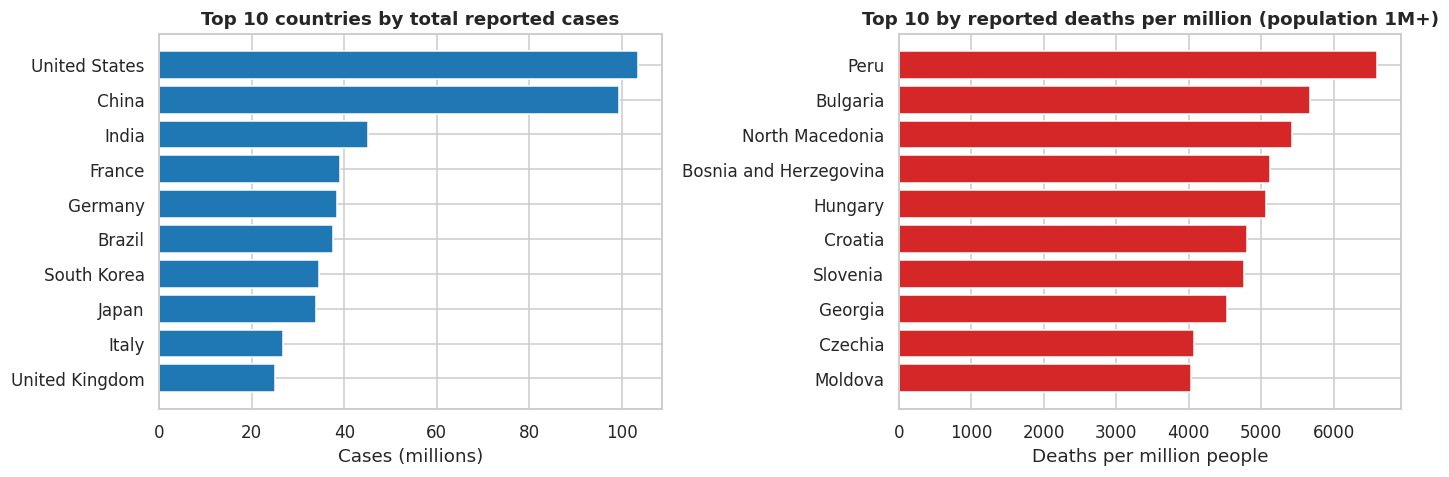

,location,total_cases,total_deaths,cfr_pct
224,United States,103436829.0,1193165.0,1.2
42,China,99373219.0,122304.0,0.1
96,India,45041748.0,533623.0,1.2
72,France,38997490.0,168091.0,0.4
78,Germany,38437756.0,174979.0,0.5
28,Brazil,37511921.0,702116.0,1.9
198,South Korea,34571873.0,35934.0,0.1
105,Japan,33803572.0,74694.0,0.2
103,Italy,26781078.0,197307.0,0.7
223,United Kingdom,24974629.0,232112.0,0.9


In [5]:
snap["cfr_pct"] = snap["total_deaths"] / snap["total_cases"] * 100        # reported deaths / reported cases
big = snap[snap["population"] >= 1_000_000].copy()                         # drop tiny populations for per-million rankings

top_cases = snap.nlargest(10, "total_cases")[["location", "total_cases", "total_deaths", "cfr_pct"]]
top_dpm = big.nlargest(10, "total_deaths_per_million")[["location", "total_deaths_per_million", "total_cases_per_million", "cfr_pct"]]

fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
ax[0].barh(top_cases["location"][::-1], top_cases["total_cases"][::-1] / 1e6, color="#1f77b4")
ax[0].set_title("Top 10 countries by total reported cases")
ax[0].set_xlabel("Cases (millions)")
ax[1].barh(top_dpm["location"][::-1], top_dpm["total_deaths_per_million"][::-1], color="#d62728")
ax[1].set_title("Top 10 by reported deaths per million (population 1M+)")
ax[1].set_xlabel("Deaths per million people")
plt.tight_layout(); save(fig, "01_global_top10.png"); plt.show()

metrics["top_cases_country"] = top_cases.iloc[0]["location"]
metrics["top_cases_millions"] = round(top_cases.iloc[0]["total_cases"] / 1e6, 1)
metrics["top_dpm_country"] = top_dpm.iloc[0]["location"]
metrics["top_dpm_value"] = int(round(top_dpm.iloc[0]["total_deaths_per_million"]))
top_cases.round(1)

Absolute totals mostly track population size. Adjusting per million people changes the ranking, so per-capita measures are the fair way to compare countries.

In [6]:
cont = (snap.dropna(subset=["continent"])
            .groupby("continent")
            .agg(total_cases=("total_cases", "sum"), total_deaths=("total_deaths", "sum"), population=("population", "sum")))
cont["cases_per_million"] = cont["total_cases"] / cont["population"] * 1e6
cont["deaths_per_million"] = cont["total_deaths"] / cont["population"] * 1e6
cont["cfr_pct"] = cont["total_deaths"] / cont["total_cases"] * 100
cont.sort_values("deaths_per_million", ascending=False).round(1)

,total_cases,total_deaths,population,cases_per_million,deaths_per_million,cfr_pct
continent,,,,,,
South America,68809418.0,1354187.0,436816679,157524.7,3100.1,2.0
Europe,252642589.0,2099271.0,745629155,338831.4,2815.4,0.8
North America,124492666.0,1671178.0,600323657,207375.9,2783.8,1.3
Oceania,15003352.0,32918.0,45038907,333119.8,730.9,0.2
Asia,301499099.0,1637249.0,4721455390,63857.2,346.8,0.5
Africa,13145380.0,259117.0,1426736614,9213.6,181.6,2.0


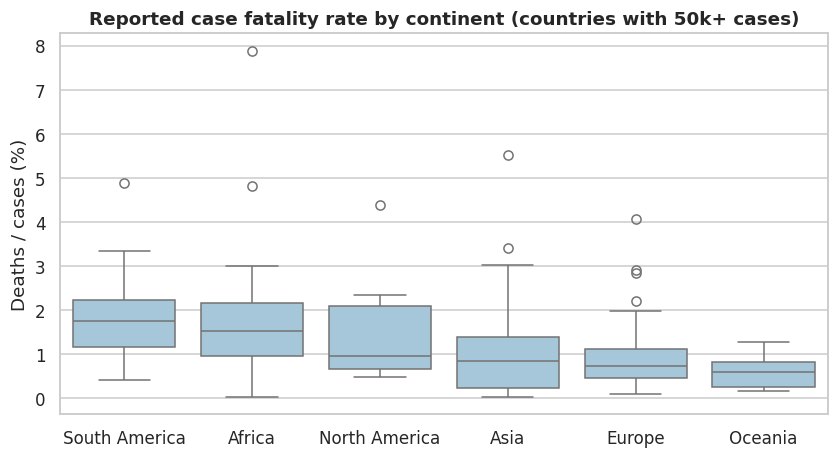

In [7]:
fig, ax = plt.subplots(figsize=(9, 4.5))
cfr_df = snap[(snap["total_cases"] >= 50_000)].dropna(subset=["continent", "cfr_pct"])
order = cfr_df.groupby("continent")["cfr_pct"].median().sort_values(ascending=False).index
sns.boxplot(data=cfr_df, x="continent", y="cfr_pct", order=order, color="#9ecae1", ax=ax)
ax.set_title("Reported case fatality rate by continent (countries with 50k+ cases)")
ax.set_xlabel(""); ax.set_ylabel("Deaths / cases (%)")
save(fig, "02_cfr_by_continent.png"); plt.show()
metrics["median_cfr_pct"] = round(cfr_df["cfr_pct"].median(), 2)

Case fatality rates differ a lot by region. This reflects testing coverage, age structure and how deaths are recorded as much as
the true severity of the disease, so a high or low CFR on its own should not be read as better or worse healthcare.

## 4. India deep dive: waves of cases and deaths

In [8]:
ind = daily[daily["location"] == "India"].set_index("date").sort_index()
ind = ind[ind["total_cases"].notna()]                 # keep dates on which India actually reported cases
print("India reporting window:", ind.index.min().date(), "to", ind.index.max().date())

# Waves are defined by calendar windows around the visible peaks (variant labels are by timing only: variant data is not in this dataset)
waves = {
    "Wave 1 (2020)":        ("2020-06-01", "2021-02-28"),
    "Wave 2 (Delta period, 2021)":    ("2021-03-01", "2021-07-31"),
    "Wave 3 (Omicron period, 2022)":  ("2021-12-15", "2022-03-31"),
}
rows = []
for name, (a, b) in waves.items():
    w = ind.loc[a:b]
    pk_c = w["new_cases_smoothed"].idxmax(); pk_d = w["new_deaths_smoothed"].idxmax()
    rows.append({"wave": name,
                 "peak_cases_date": pk_c.date(), "peak_7d_avg_cases": round(w["new_cases_smoothed"].max()),
                 "peak_deaths_date": pk_d.date(), "peak_7d_avg_deaths": round(w["new_deaths_smoothed"].max()),
                 "cases_in_window": round(w["new_cases"].sum()), "deaths_in_window": round(w["new_deaths"].sum())})
wave_tbl = pd.DataFrame(rows)
wave_tbl["deaths_per_1000_cases"] = (wave_tbl["deaths_in_window"] / wave_tbl["cases_in_window"] * 1000).round(1)
wave_tbl

India reporting window: 2020-01-05 to 2024-08-04


,wave,peak_cases_date,peak_7d_avg_cases,peak_deaths_date,peak_7d_avg_deaths,cases_in_window,deaths_in_window,deaths_per_1000_cases
0,Wave 1 (2020),2020-09-20,92323,2020-09-20,1167,10914588,151887,13.9
1,"Wave 2 (Delta period, 2021)",2021-05-09,391280,2021-05-23,4140,20275170,263500,13.0
2,"Wave 3 (Omicron period, 2022)",2022-01-23,302157,2022-02-06,1127,8328943,45570,5.5


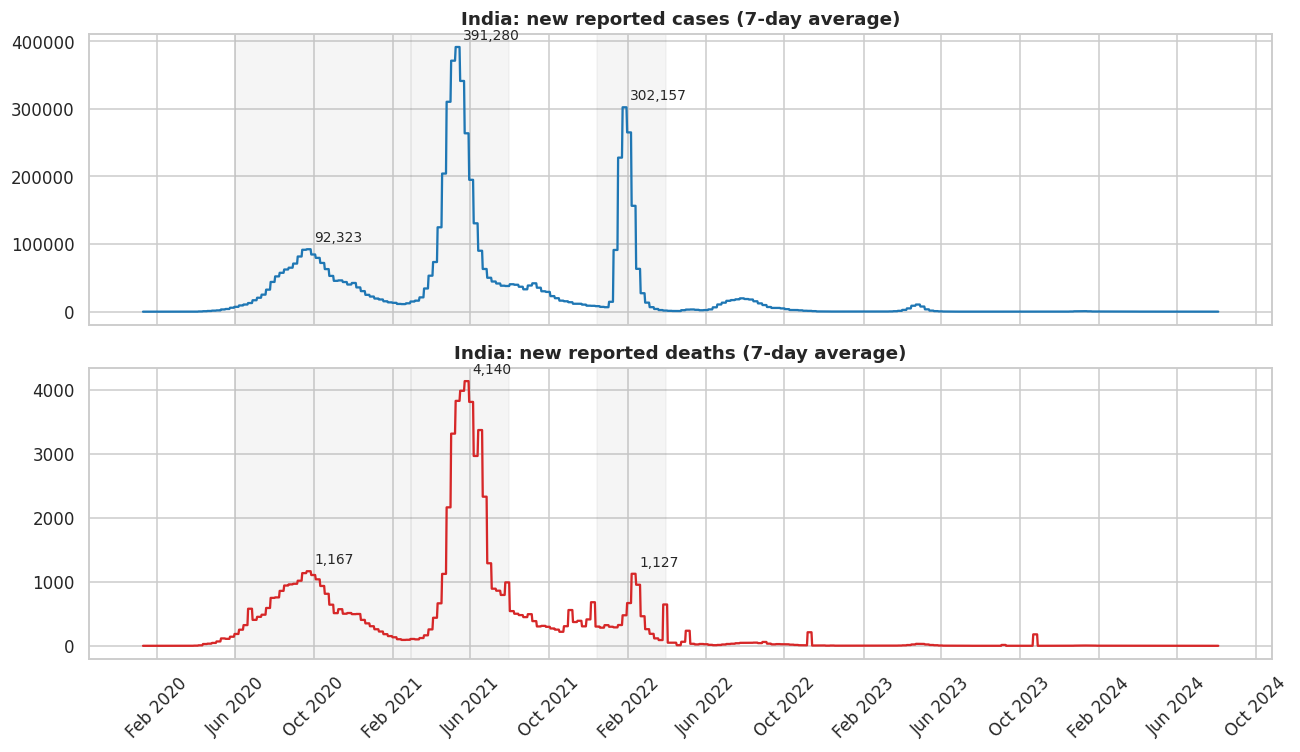

In [9]:
fig, ax = plt.subplots(2, 1, figsize=(12, 7), sharex=True)
ax[0].plot(ind.index, ind["new_cases_smoothed"], color="#1f77b4")
ax[1].plot(ind.index, ind["new_deaths_smoothed"], color="#d62728")
for a_ in ax:
    for name, (s, e) in waves.items():
        a_.axvspan(pd.Timestamp(s), pd.Timestamp(e), color="grey", alpha=0.08)
for _, r in wave_tbl.iterrows():
    ax[0].annotate(f"{r['peak_7d_avg_cases']:,}", (pd.Timestamp(r["peak_cases_date"]), r["peak_7d_avg_cases"]),
                   textcoords="offset points", xytext=(5, 5), fontsize=9)
    ax[1].annotate(f"{r['peak_7d_avg_deaths']:,}", (pd.Timestamp(r["peak_deaths_date"]), r["peak_7d_avg_deaths"]),
                   textcoords="offset points", xytext=(5, 5), fontsize=9)
ax[0].set_title("India: new reported cases (7-day average)")
ax[1].set_title("India: new reported deaths (7-day average)")
ax[1].xaxis.set_major_locator(mdates.MonthLocator(interval=4)); ax[1].xaxis.set_major_formatter(mdates.DateFormatter("%b %Y"))
plt.xticks(rotation=45); plt.tight_layout(); save(fig, "03_india_waves.png"); plt.show()

w2 = wave_tbl.iloc[1]
metrics["india_wave2_peak_cases"] = int(w2["peak_7d_avg_cases"]); metrics["india_wave2_peak_date"] = str(w2["peak_cases_date"])
metrics["india_wave2_peak_deaths"] = int(w2["peak_7d_avg_deaths"]); metrics["india_wave2_peak_deaths_date"] = str(w2["peak_deaths_date"])
metrics["india_wave3_peak_cases"] = int(wave_tbl.iloc[2]["peak_7d_avg_cases"]); metrics["india_wave3_peak_date"] = str(wave_tbl.iloc[2]["peak_cases_date"])
metrics["india_wave3_deaths_per_1000_cases"] = float(wave_tbl.iloc[2]["deaths_per_1000_cases"])
metrics["india_wave2_deaths_per_1000_cases"] = float(w2["deaths_per_1000_cases"])
metrics["india_total_cases_m"] = round(ind["total_cases"].iloc[-1] / 1e6, 1)
metrics["india_total_deaths"] = int(ind["total_deaths"].dropna().iloc[-1])

**Reading the chart:** deaths peak after cases (deaths lag infections by a few weeks), and the third wave produced far
fewer deaths per reported case than the second. The `deaths_per_1000_cases` column makes that comparison explicit.
Possible reasons include rising vaccination and prior infection, but this dataset cannot prove the cause.

## 5. How does India compare with other large countries?

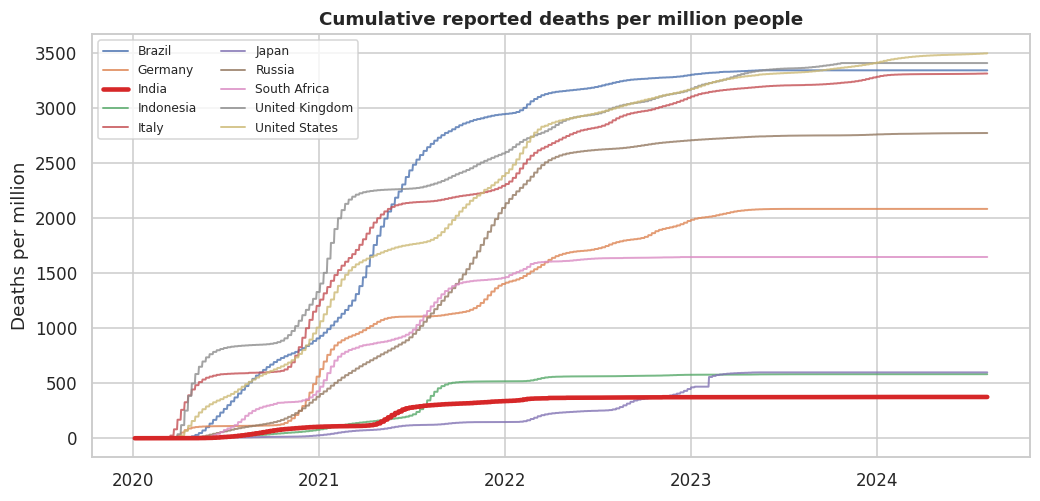

,location,total_cases_per_million,total_deaths_per_million,cfr_pct,median_age
0,United States,302859.5,3493.6,1.2,38.3
1,United Kingdom,366308.0,3404.4,0.9,40.8
2,Brazil,178367.9,3338.5,1.9,33.5
3,Italy,449202.9,3309.5,0.7,47.9
4,Russia,166703.8,2769.5,1.7,39.6
5,Germany,457123.1,2081.0,0.5,46.6
6,South Africa,65291.2,1644.7,2.5,27.3
7,Japan,270433.8,597.6,0.2,48.2
8,Indonesia,24493.0,581.2,2.4,29.3
9,India,31598.9,374.4,1.2,28.2


In [10]:
fig, ax = plt.subplots(figsize=(11, 5))
for loc, g in daily.groupby("location"):
    g = g.dropna(subset=["total_deaths_per_million"])
    is_in = loc == "India"
    ax.plot(g["date"], g["total_deaths_per_million"], label=loc,
            lw=3 if is_in else 1.3, color="#d62728" if is_in else None, alpha=1 if is_in else 0.8, zorder=3 if is_in else 2)
ax.set_title("Cumulative reported deaths per million people")
ax.set_ylabel("Deaths per million"); ax.legend(ncol=2, fontsize=8, frameon=True)
save(fig, "04_deaths_per_million_selected.png"); plt.show()

cmp_ = snap[snap["location"].isin(selected)][["location", "total_cases_per_million", "total_deaths_per_million", "cfr_pct", "median_age"]]
cmp_ = cmp_.sort_values("total_deaths_per_million", ascending=False).round(1).reset_index(drop=True)
india_rank = int(cmp_.index[cmp_["location"] == "India"][0]) + 1
metrics["india_dpm"] = float(cmp_.loc[cmp_["location"] == "India", "total_deaths_per_million"].iloc[0])
metrics["india_cfr_pct"] = float(cmp_.loc[cmp_["location"] == "India", "cfr_pct"].iloc[0])
metrics["india_rank_among_10_by_dpm"] = india_rank
metrics["highest_dpm_in_10"] = cmp_.iloc[0]["location"]; metrics["highest_dpm_in_10_value"] = float(cmp_.iloc[0]["total_deaths_per_million"])
cmp_

## 6. Vaccination and policy in India

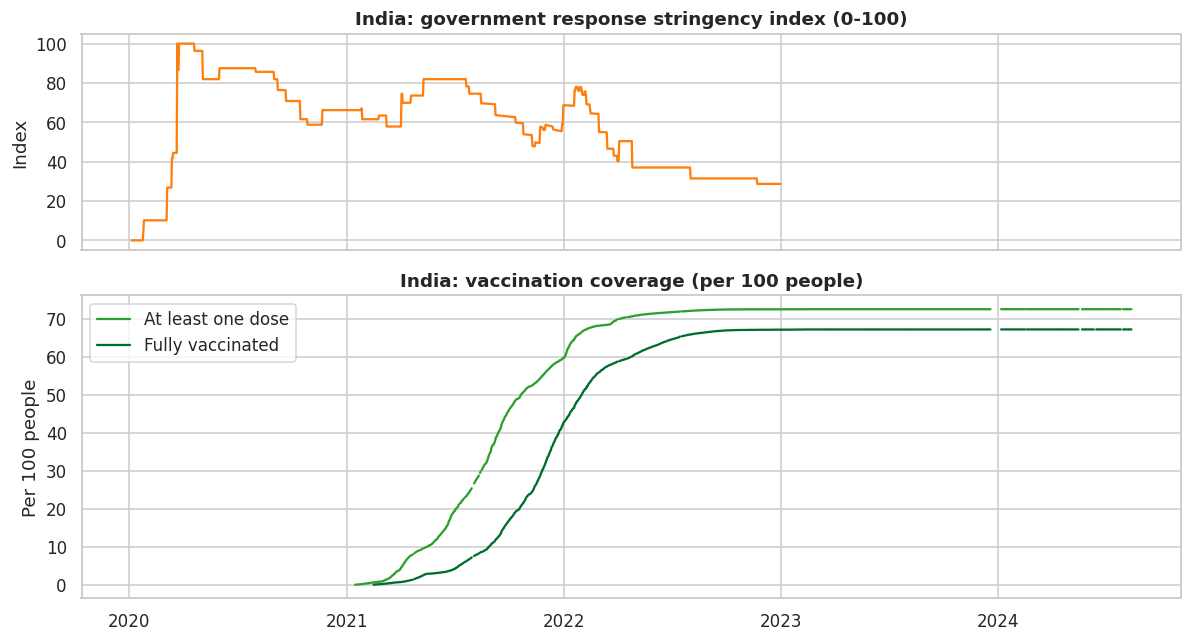

Peak stringency: 100.0 | first dose reached 50 per 100 on: 2021-10-21


In [11]:
vac = daily[daily["location"] == "India"].set_index("date").sort_index()
fig, ax = plt.subplots(2, 1, figsize=(11, 6), sharex=True, gridspec_kw={"height_ratios": [1, 1.4]})
ax[0].plot(vac.index, vac["stringency_index"], color="#ff7f0e")
ax[0].set_title("India: government response stringency index (0-100)"); ax[0].set_ylabel("Index")
ax[1].plot(vac.index, vac["people_vaccinated_per_hundred"], label="At least one dose", color="#2ca02c")
ax[1].plot(vac.index, vac["people_fully_vaccinated_per_hundred"], label="Fully vaccinated", color="#006d2c")
ax[1].set_title("India: vaccination coverage (per 100 people)"); ax[1].set_ylabel("Per 100 people"); ax[1].legend()
plt.tight_layout(); save(fig, "05_india_vaccination_policy.png"); plt.show()

v1 = vac["people_vaccinated_per_hundred"].dropna()
metrics["india_max_one_dose_per_100"] = round(v1.max(), 1)
metrics["india_max_full_per_100"] = round(vac["people_fully_vaccinated_per_hundred"].dropna().max(), 1)
first50 = v1[v1 >= 50]
metrics["india_50pct_one_dose_date"] = str(first50.index[0].date()) if len(first50) else "not reached in data"
metrics["india_peak_stringency"] = round(vac["stringency_index"].max(), 1)
print("Peak stringency:", metrics["india_peak_stringency"], "| first dose reached 50 per 100 on:", metrics["india_50pct_one_dose_date"])

## 7. What goes with higher reported deaths across countries?

In [12]:
feat = {"median_age": "Median age", "aged_65_older": "Population aged 65+ (%)", "gdp_per_capita": "GDP per capita",
        "human_development_index": "Human development index", "max_people_vaccinated_per_hundred": "Peak vaccination (1+ dose per 100)"}
d = big.dropna(subset=["total_deaths_per_million"] + list(feat)).copy()
corr = pd.Series({lab: d[col].corr(d["total_deaths_per_million"], method="spearman") for col, lab in feat.items()}).sort_values()
print(f"Countries used: {len(d)}")
corr.round(2)

Countries used: 151


Peak vaccination (1+ dose per 100)    0.34
GDP per capita                        0.66
Human development index               0.76
Population aged 65+ (%)               0.78
Median age                            0.79
dtype: float64

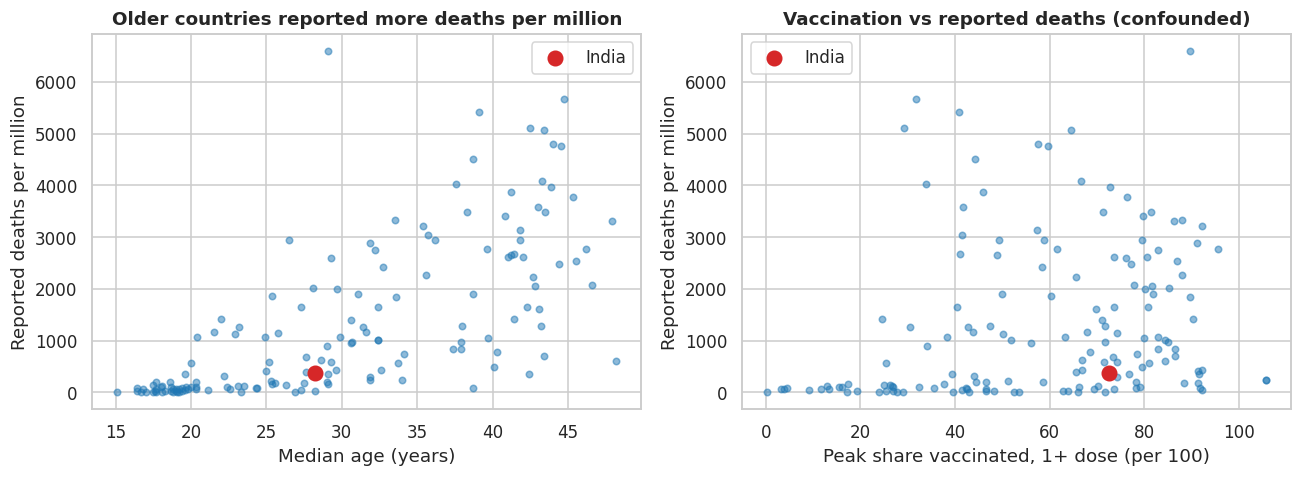

In [13]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
for a_, col, lab in zip(ax, ["median_age", "max_people_vaccinated_per_hundred"], ["Median age (years)", "Peak share vaccinated, 1+ dose (per 100)"]):
    a_.scatter(d[col], d["total_deaths_per_million"], s=18, alpha=0.5, color="#1f77b4")
    hi = d[d["location"] == "India"]
    a_.scatter(hi[col], hi["total_deaths_per_million"], s=90, color="#d62728", zorder=3, label="India")
    a_.set_xlabel(lab); a_.set_ylabel("Reported deaths per million"); a_.legend()
ax[0].set_title("Older countries reported more deaths per million")
ax[1].set_title("Vaccination vs reported deaths (confounded)")
plt.tight_layout(); save(fig, "06_drivers_scatter.png"); plt.show()

metrics["spearman_median_age"] = round(corr["Median age"], 2)
metrics["spearman_gdp"] = round(corr["GDP per capita"], 2)
metrics["spearman_vaccination"] = round(corr["Peak vaccination (1+ dose per 100)"], 2)
metrics["countries_in_corr"] = int(len(d))

**Careful interpretation:** these are country-level correlations (ecological data), not proof of cause. Richer, older countries
tend to record more deaths per million, partly because older people face higher risk and partly because richer countries
test and record deaths more completely. Vaccination coverage is mixed up with age, income and reporting quality, so a simple
correlation between vaccination and deaths cannot be read as the effect of vaccines.

## 8. Key findings

In [14]:
m = metrics
print(f"1. Largest total: {m['top_cases_country']} ({m['top_cases_millions']}M reported cases). Highest deaths per million (pop. 1M+): {m['top_dpm_country']} ({m['top_dpm_value']:,}).")
print(f"2. India reported {m['india_total_cases_m']}M cases and {m['india_total_deaths']:,} deaths. Its reported deaths per million ({m['india_dpm']:.0f}) rank {m['india_rank_among_10_by_dpm']} of the 10 large countries analysed (1 = highest); {m['highest_dpm_in_10']} is highest at {m['highest_dpm_in_10_value']:.0f}.")
print(f"3. India's second wave peaked at {m['india_wave2_peak_cases']:,} cases/day on {m['india_wave2_peak_date']} and {m['india_wave2_peak_deaths']:,} deaths/day on {m['india_wave2_peak_deaths_date']}.")
print(f"4. The third wave peaked at {m['india_wave3_peak_cases']:,} cases/day ({m['india_wave3_peak_date']}) but had {m['india_wave3_deaths_per_1000_cases']} deaths per 1,000 cases versus {m['india_wave2_deaths_per_1000_cases']} in wave 2.")
print(f"5. Across {m['countries_in_corr']} countries, reported deaths per million correlate with median age (Spearman {m['spearman_median_age']}) and GDP per capita ({m['spearman_gdp']}), and with peak vaccination ({m['spearman_vaccination']}), which reflects confounding and reporting differences, not a vaccine effect.")
print(f"6. Median reported case fatality rate across countries with 50k+ cases: {m['median_cfr_pct']}%.")

1. Largest total: United States (103.4M reported cases). Highest deaths per million (pop. 1M+): Peru (6,601).
2. India reported 45.0M cases and 533,623 deaths. Its reported deaths per million (374) rank 10 of the 10 large countries analysed (1 = highest); United States is highest at 3494.
3. India's second wave peaked at 391,280 cases/day on 2021-05-09 and 4,140 deaths/day on 2021-05-23.
4. The third wave peaked at 302,157 cases/day (2022-01-23) but had 5.5 deaths per 1,000 cases versus 13.0 in wave 2.
5. Across 151 countries, reported deaths per million correlate with median age (Spearman 0.79) and GDP per capita (0.66), and with peak vaccination (0.34), which reflects confounding and reporting differences, not a vaccine effect.
6. Median reported case fatality rate across countries with 50k+ cases: 0.99%.


## 9. Limitations
- **Reported data only.** Cases depend on testing, and deaths depend on how each country counts Covid-19 deaths. Official counts are widely believed to understate true mortality in many countries, including India, where excess-mortality estimates are far higher than reported deaths.
- **Countries stopped reporting at different dates**, so the latest values are not all from the same day.
- **Wave windows are chosen by date**, based on visible peaks, not by an algorithm or variant sequencing data.
- **Country-level correlations are not causal** (ecological fallacy), and the sample excludes countries with population under 1 million.
- Dataset: Our World in Data Covid-19 dataset (Mathieu et al., compiled from Johns Hopkins University CSSE, WHO and national sources).

In [15]:
with open(DATA / "key_metrics.json", "w") as f:
    json.dump(metrics, f, indent=2, default=str)
print("Saved key metrics:", len(metrics))

Saved key metrics: 28
